# 01 · From market intervals to bilateral weather controls

**Synthetic illustration — Not empirical research results**

The research asks whether electricity exports toward Italy change around the
CBAM policy cutoff. Before estimating anything, delivery intervals, flow signs,
prices and weather need compatible definitions. This notebook follows that
chain using tiny invented examples and the package's existing transformations.

**Learn to:** audit hourly aggregation; distinguish power from energy; keep UTC
keys through DST; and aggregate weather without changing vector or time semantics.
No API, private input root, genuine geographic boundary or research result is used.
Run all cells in a fresh kernel. See [methodology and research limitations](../docs/methodology.md).


In [1]:
import numpy as np
import pandas as pd
# Keep table outputs plain text for the public safety profile.
pd.set_option("display.notebook_repr_html", False)
import matplotlib.pyplot as plt
from IPython.display import display

LABEL = "Synthetic illustration — Not empirical research results"
plt.rcParams.update({"figure.facecolor": "white", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 12,
                     "axes.labelsize": 10, "font.size": 10})
DEMO_LABEL = "SYNTHETIC DATA — NOT EMPIRICAL RESEARCH RESULTS"
print(DEMO_LABEL)
print(LABEL)


SYNTHETIC DATA — NOT EMPIRICAL RESEARCH RESULTS
Synthetic illustration — Not empirical research results


## 1. Preserve the signed flow before taking its positive part

For Italy-reporter flow, positive means inward toward Italy. A full-hour mean
of power is $\bar P_h=\sum_j P_j\Delta t_j/60$ in MW; its one-hour energy is
$E_h=\bar P_h\times1\,\mathrm{h}$ in MWh. Their numerical values coincide for
a one-hour interval, but their units and interpretation differ.

The export proxy is $\max(\bar P_h,0)$. Taking positive parts first changes the
quantity. The package requires all 60 valid minutes; it does not fill a missing quarter.


In [2]:
from cbam_power.market import integrate_native

times = pd.date_range("2026-01-03T00:00Z", periods=8, freq="15min")
signed_mw = np.array([-40., 80., -40., 80., 60., 60., 60., 60.])
hourly = integrate_native(times, signed_mw, 15, "net_MW")
early_positive = integrate_native(times, np.maximum(signed_mw, 0), 15, "wrong_proxy")
comparison = hourly[["net_MW", "integrated_MWh_if_power", "valid_minutes"]].copy()
comparison["positive_after_hourly_MW"] = hourly.net_MW.clip(lower=0)
comparison["positive_before_hourly_MW"] = early_positive.wrong_proxy
assert comparison.iloc[0].positive_after_hourly_MW == 20
assert comparison.iloc[0].positive_before_hourly_MW == 40
display(comparison)

damaged = signed_mw.copy()
damaged[1] = np.nan
missing = integrate_native(times, damaged, 15, "net_MW")
assert pd.isna(missing.iloc[0].net_MW)
assert missing.iloc[0].valid_minutes == 45
print("An incomplete hour remains missing; no zero fill or rescaling.")


                           net_MW  integrated_MWh_if_power  valid_minutes  \
timestamp_utc                                                               
2026-01-03 00:00:00+00:00    20.0                     20.0           60.0   
2026-01-03 01:00:00+00:00    60.0                     60.0           60.0   

                           positive_after_hourly_MW  positive_before_hourly_MW  
timestamp_utc                                                                   
2026-01-03 00:00:00+00:00                      20.0                       40.0  
2026-01-03 01:00:00+00:00                      60.0                       60.0  

An incomplete hour remains missing; no zero fill or rescaling.


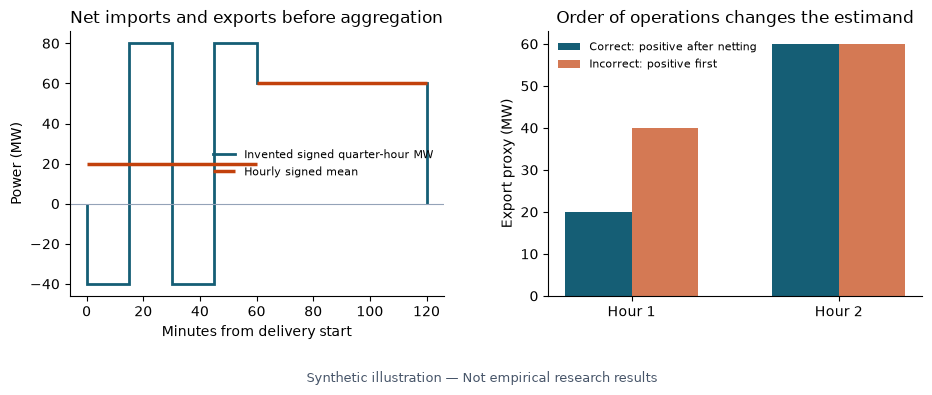

In [3]:
interval_figure, axes = plt.subplots(1, 2, figsize=(11, 4.2))
minutes = np.arange(len(signed_mw)) * 15
axes[0].stairs(signed_mw, np.arange(len(signed_mw)+1)*15,
               color="#155e75", linewidth=2, label="Invented signed quarter-hour MW")
for index, value in enumerate(hourly.net_MW):
    axes[0].hlines(value, index*60, (index+1)*60, color="#c2410c", linewidth=2.5,
                   label="Hourly signed mean" if index == 0 else None)
axes[0].axhline(0, color="#94a3b8", linewidth=.8)
axes[0].set(xlabel="Minutes from delivery start", ylabel="Power (MW)",
            title="Net imports and exports before aggregation")
axes[0].legend(frameon=False, fontsize=8)
positions = np.arange(len(comparison))
axes[1].bar(positions-.16, comparison.positive_after_hourly_MW, width=.32,
            label="Correct: positive after netting", color="#155e75")
axes[1].bar(positions+.16, comparison.positive_before_hourly_MW, width=.32,
            label="Incorrect: positive first", color="#c2410c", alpha=.7)
axes[1].set(xticks=positions, xticklabels=["Hour 1", "Hour 2"], ylabel="Export proxy (MW)",
            title="Order of operations changes the estimand")
axes[1].legend(frameon=False, fontsize=8)
interval_figure.text(.5, .025, LABEL, ha="center", fontsize=9, color="#475569")
interval_figure.subplots_adjust(bottom=.23, top=.86, wspace=.28)
plt.show()


## 2. Keep delivery keys in UTC; use Rome only for calendar variables

Two UTC hours can share the same local clock hour when daylight saving ends.
The offset distinguishes them. The policy instant is **2026-01-01 00:00 in
Europe/Rome**, equivalent to **2025-12-31 23:00 UTC**. The running variable uses
delivery midpoints; `Post` uses delivery starts. Prices retain the definition
destination minus origin, with an explicitly supplied pre-policy center.


In [4]:
utc = pd.date_range("2025-10-26T00:00Z", periods=4, freq="h")
display(pd.DataFrame({"UTC_delivery_start": utc,
                      "Rome_clock_with_offset": utc.tz_convert("Europe/Rome").astype(str)}))
cutoff = pd.Timestamp("2026-01-01", tz="Europe/Rome").tz_convert("UTC")
assert cutoff == pd.Timestamp("2025-12-31T23:00Z")
print("Policy instant in UTC:", cutoff)


         UTC_delivery_start     Rome_clock_with_offset
0 2025-10-26 00:00:00+00:00  2025-10-26 02:00:00+02:00
1 2025-10-26 01:00:00+00:00  2025-10-26 02:00:00+01:00
2 2025-10-26 02:00:00+00:00  2025-10-26 03:00:00+01:00
3 2025-10-26 03:00:00+00:00  2025-10-26 04:00:00+01:00

Policy instant in UTC: 2025-12-31 23:00:00+00:00


## 3. Spatial means must preserve wind and accumulation semantics

These are **invented two-cell weights**, not GISCO polygons or ERA5 observations.
With weights $w=(0.25,0.75)$, temperature is converted from K to °C before its
spatial mean. Wind is $\sum_i w_i\sqrt{u_i^2+v_i^2}$: averaging the components
first would cancel opposing winds. SSRD is divided by 3,600; precipitation in
metres is multiplied by 1,000. Both accumulated variables shift their validity
timestamps back one hour to the delivery start. Instantaneous variables do not.


In [5]:
from cbam_power.weather import weighted_fields, geodesic_area
from shapely.geometry import box

semantics = {"variables": {}}
for name, scale, offset, shift, output in [
    ("t2m", 1., -273.15, 0, "temp_c"),
    ("ssrd", 1/3600, 0., -1, "ssrd_processed"),
    ("tp", 1000., 0., -1, "tp_processed")]:
    semantics["variables"][name] = dict(scale=scale, offset=offset,
        delivery_start_offset_hours=shift, output=output)
weights = np.array([.25, .75])
grids = {"t2m": np.array([[273.15, 293.15]]),
         "u10": np.array([[3., -3.]]), "v10": np.array([[4., -4.]]),
         "ssrd": np.array([[7200., 3600.]]), "tp": np.array([[.002, .006]])}
fields = weighted_fields(grids, weights, semantics)
validity = pd.Timestamp("2026-01-03T01:00Z")
display(pd.DataFrame([{"variable": name, "value": values[0],
                      "delivery_start": validity + pd.Timedelta(hours=shift)}
                     for name, (values, shift) in fields.items()]))
assert np.isclose(fields["temp_c"][0][0], 15.)
assert np.isclose(fields["wind_ms"][0][0], 5.)
assert np.isclose(fields["ssrd_processed"][0][0], 1.25)
assert np.isclose(fields["tp_processed"][0][0], 5.)
wrong_wind = np.hypot(grids["u10"] @ weights, grids["v10"] @ weights)[0]
print("Magnitude first: 5 m/s; components first:", wrong_wind, "m/s")
print("Artificial 0.25° WGS84 cell area (km²):",
      round(geodesic_area(box(-.125, -.125, .125, .125)) / 1e6, 2))
bad_grid = {name: values.copy() for name, values in grids.items()}
bad_grid["t2m"][0, 1] = np.nan
assert np.isnan(weighted_fields(bad_grid, weights, semantics)["temp_c"][0][0])


         variable  value            delivery_start
0          temp_c  15.00 2026-01-03 01:00:00+00:00
1  ssrd_processed   1.25 2026-01-03 00:00:00+00:00
2    tp_processed   5.00 2026-01-03 00:00:00+00:00
3         wind_ms   5.00 2026-01-03 01:00:00+00:00

Magnitude first: 5 m/s; components first: 2.5 m/s
Artificial 0.25° WGS84 cell area (km²): 769.32


### From a polygon to auditable area weights

The next example creates an original polygon across **six invented 0.25° cells**.
It is not a map of any study region. For cell $C_i$ and polygon $G$,
$w_i=A(C_i\cap G)/\sum_j A(C_j\cap G)$; WGS84 geodesic area is evaluated by
the existing package function. Its weight validator checks cell alignment,
uniqueness, positivity and normalization. The diagram exposes the numerator
and the resulting weights instead of silently selecting nearby grid points.

This construction is permitted only for this artificial fixture. The actual
research reads its frozen masks and weights; this notebook neither loads nor
replaces them.


  cell  latitude  longitude  intersection_km2  area_weight
0   C1      0.00       0.00         501.89276      0.21018
1   C2      0.00       0.25         571.10532      0.23916
2   C3      0.00       0.50         207.52843      0.08691
3   C4      0.25       0.00         206.41787      0.08644
4   C5      0.25       0.25         591.84898      0.24785
5   C6      0.25       0.50         309.16135      0.12947

               region        variable      value  delivery_offset_hours
0  ARTIFICIAL_POLYGON          temp_c  10.153266                      0
1  ARTIFICIAL_POLYGON  ssrd_processed   1.017732                     -1
2  ARTIFICIAL_POLYGON    tp_processed   1.659891                     -1
3  ARTIFICIAL_POLYGON         wind_ms   4.350880                      0

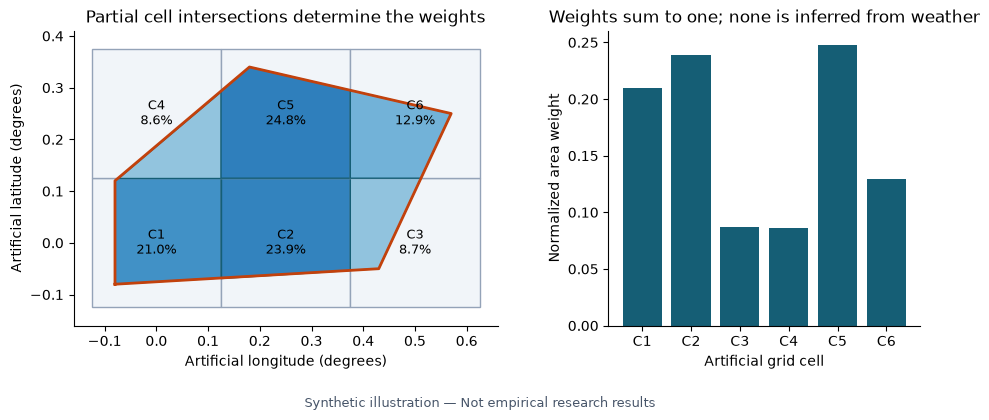

In [6]:
from shapely.geometry import Polygon
from matplotlib.patches import Polygon as PolygonPatch
from cbam_power.weather import validate_weights

artificial_region = Polygon([(-.08, -.08), (.43, -.05), (.57, .25),
                             (.18, .34), (-.08, .12)])
cell_records, cell_geometries, intersections = [], [], []
for latitude in [0., .25]:
    for longitude in [0., .25, .5]:
        cell = box(longitude-.125, latitude-.125, longitude+.125, latitude+.125)
        intersection = artificial_region.intersection(cell)
        cell_geometries.append(cell)
        intersections.append(intersection)
        cell_records.append(dict(latitude=latitude, longitude=longitude,
            intersection_area_m2=geodesic_area(intersection)))
artificial_mask = pd.DataFrame(cell_records)
artificial_mask["area_weight"] = (artificial_mask.intersection_area_m2 /
                                   artificial_mask.intersection_area_m2.sum())
spatial_weights = validate_weights(artificial_mask)
assert artificial_region.is_valid and len(spatial_weights) == 6
assert np.isclose(spatial_weights.sum(), 1., atol=1e-12, rtol=0)
display(artificial_mask.assign(cell=[f"C{i}" for i in range(1, 7)],
    intersection_km2=artificial_mask.intersection_area_m2/1e6)
    [["cell", "latitude", "longitude", "intersection_km2", "area_weight"]].round(5))

spatial_grids = {"t2m": np.array([[281., 283., 285., 282., 284., 286.]]),
    "u10": np.array([[3., -3., 0., 4., -4., 0.]]),
    "v10": np.array([[4., -4., 2., 3., -3., -2.]]),
    "ssrd": np.array([[3600., 5400., 7200., 900., 1800., 3600.]]),
    "tp": np.array([[.001, .002, .001, .003, .002, .001]])}
region_fields = weighted_fields(spatial_grids, spatial_weights, semantics)
display(pd.DataFrame([{"region": "ARTIFICIAL_POLYGON", "variable": key,
    "value": float(value[0]), "delivery_offset_hours": shift}
    for key, (value, shift) in region_fields.items()]))

grid_figure, axes = plt.subplots(1, 2, figsize=(11, 4.4),
                                gridspec_kw={"width_ratios": [1.4, 1]})
for index, (cell, intersection, weight) in enumerate(zip(cell_geometries, intersections, spatial_weights)):
    axes[0].add_patch(PolygonPatch(np.asarray(cell.exterior.coords), closed=True,
                                   facecolor="#f1f5f9", edgecolor="#94a3b8"))
    axes[0].add_patch(PolygonPatch(np.asarray(intersection.exterior.coords), closed=True,
                                   facecolor=plt.cm.Blues(.25+1.8*weight), edgecolor="#155e75"))
    center = cell.centroid
    axes[0].text(center.x, center.y, f"C{index+1}\n{weight:.1%}", ha="center", va="center", fontsize=9)
outline = np.asarray(artificial_region.exterior.coords)
axes[0].plot(outline[:, 0], outline[:, 1], color="#c2410c", linewidth=2)
axes[0].set(xlim=(-.16, .66), ylim=(-.16, .41), aspect="equal",
            xlabel="Artificial longitude (degrees)", ylabel="Artificial latitude (degrees)",
            title="Partial cell intersections determine the weights")
axes[1].bar([f"C{i}" for i in range(1, 7)], spatial_weights, color="#155e75")
axes[1].set(xlabel="Artificial grid cell", ylabel="Normalized area weight",
            title="Weights sum to one; none is inferred from weather")
grid_figure.text(.5, .025, LABEL, ha="center", fontsize=9, color="#475569")
grid_figure.subplots_adjust(bottom=.21, top=.88, wspace=.28)
plt.show()


A cell can receive a small weight even when its center is inside the polygon;
the covered area is what matters. Each output field uses the same mask, with
variable-specific conversion and timing. A missing required cell propagates
to the regional value rather than changing these weights.


## 4. Assemble an artificial five-corridor panel

The example below reuses the package's artificial native series and weather
generator. Corridor names demonstrate the schema; their values have no empirical
meaning. Both origin and destination weather join on geography plus UTC hour.
The supplied price center of 10 is an invented input, not an estimated research value.


In [7]:
from cbam_power._demo import artificial_native, artificial_weather
from cbam_power.panel import assemble_panel

native_times, native_values = artificial_native()
blocks = []
for index, corridor in enumerate(["AT_IT", "CH_IT", "SI_IT", "GR_IT", "ME_IT"]):
    block = integrate_native(native_times, native_values + 10 * index,
                             15, "commercial_net_MW").reset_index()
    block = block[["timestamp_utc", "commercial_net_MW"]]
    block = block.assign(corridor_id=corridor,
                         physical_net_MW=block.commercial_net_MW * .95,
                         origin_price=60., destination_price=70., spread_center=10.)
    blocks.append(block)
weather = artificial_weather(pd.DatetimeIndex(native_times.floor("h").unique()))
# Different invented temperatures make the bilateral join visible.
weather.loc[weather.geography.eq("ME"), "temp_c"] += 2.
weather.loc[weather.geography.eq("IT-CSUD"), "temp_c"] -= 1.
panel = assemble_panel(pd.concat(blocks, ignore_index=True), weather)
assert not panel.duplicated(["corridor_id", "timestamp_utc"]).any()
assert panel.weather_complete.all()
assert panel.S_native.eq(10).all() and panel.spread_c.eq(0).all()
display(panel.groupby("corridor_id").agg(hours=("timestamp_utc", "size"),
    destination=("destination_bidding_zone", "first"), weather_complete=("weather_complete", "all")))
print("Artificial panel shape:", panel.shape)

bilateral_table = panel.groupby("corridor_id", as_index=False).agg(
    origin_temp_c=("origin_weather_temp_c", "first"),
    destination_temp_c=("destination_weather_temp_c", "first"),
    price_spread=("S_native", "first"), centered_spread=("spread_c", "first"))
display(bilateral_table)
assert bilateral_table.loc[bilateral_table.corridor_id.eq("ME_IT"), "origin_temp_c"].iloc[0] == 17.
assert bilateral_table.loc[bilateral_table.corridor_id.eq("ME_IT"), "destination_temp_c"].iloc[0] == 14.


             hours destination  weather_complete
corridor_id                                     
AT_IT          480     IT-NORD              True
CH_IT          480     IT-NORD              True
GR_IT          480      IT-SUD              True
ME_IT          480     IT-CSUD              True
SI_IT          480     IT-NORD              True

Artificial panel shape: (2400, 40)


  corridor_id  origin_temp_c  destination_temp_c  price_spread  \
0       AT_IT           15.0                15.0          10.0   
1       CH_IT           15.0                15.0          10.0   
2       GR_IT           15.0                15.0          10.0   
3       ME_IT           17.0                14.0          10.0   
4       SI_IT           15.0                15.0          10.0   

   centered_spread  
0              0.0  
1              0.0  
2              0.0  
3              0.0  
4              0.0  

## What this establishes—and what it does not

The arithmetic and joins are executable; a complete artificial panel does not
establish genuine annual weather coverage. The real package retains V1 frozen
inheritance, provider restrictions, raw-file identities, frozen geographic
weights and original missing observations. No interpolation or new boundary is
authorized by this illustration. Continue with
[RDiT and HAC](02_rdit_and_hac.ipynb) or the [methodology](../docs/methodology.md).


## Reproducible numerical checkpoints

The following values summarize this artificial run. The teaching runner
compares them across clean-kernel executions; they are not empirical
baselines. All values come from the calculations above, with no private
inputs or fitted research values. Presentation rounding does not change
the unrounded checkpoints.


In [8]:
PUBLIC_NUMERICAL_CHECKPOINTS = {
    "example": "DEMO_DATA_WEATHER",
    "first_hour_net_MW": float(hourly.net_MW.iloc[0]),
    "first_hour_energy_MWh": float(hourly.integrated_MWh_if_power.iloc[0]),
    "wrong_positive_first_MW": float(early_positive.wrong_proxy.iloc[0]),
    "incomplete_hour_is_missing": bool(pd.isna(missing.net_MW.iloc[0])),
    "incomplete_valid_minutes": int(missing.valid_minutes.iloc[0]),
    "dst_rome_hour_sequence": [int(v) for v in utc.tz_convert("Europe/Rome").hour],
    "two_cell_temp_c": float(fields["temp_c"][0][0]),
    "two_cell_wind_ms": float(fields["wind_ms"][0][0]),
    "wrong_component_first_wind_ms": float(wrong_wind),
    "two_cell_ssrd_W_m2": float(fields["ssrd_processed"][0][0]),
    "two_cell_tp_mm_hour": float(fields["tp_processed"][0][0]),
    "spatial_weight_sum": float(spatial_weights.sum()),
    "spatial_weights": [float(v) for v in spatial_weights],
    "intersection_area_m2": float(artificial_mask.intersection_area_m2.sum()),
    "regional_temp_c": float(region_fields["temp_c"][0][0]),
    "regional_wind_ms": float(region_fields["wind_ms"][0][0]),
    "panel_rows": int(len(panel)), "panel_columns": int(len(panel.columns)),
    "bilateral_complete_rows": int(panel.weather_complete.sum()),
    "invented_ME_origin_temp_c": float(bilateral_table.loc[bilateral_table.corridor_id.eq("ME_IT"), "origin_temp_c"].iloc[0]),
    "invented_ME_destination_temp_c": float(bilateral_table.loc[bilateral_table.corridor_id.eq("ME_IT"), "destination_temp_c"].iloc[0])}


import json
json.dumps(PUBLIC_NUMERICAL_CHECKPOINTS, allow_nan=False, sort_keys=True)
display(pd.DataFrame({"checkpoint": list(PUBLIC_NUMERICAL_CHECKPOINTS),
                      "value": list(PUBLIC_NUMERICAL_CHECKPOINTS.values())}))


                        checkpoint  \
0                          example   
1                first_hour_net_MW   
2            first_hour_energy_MWh   
3          wrong_positive_first_MW   
4       incomplete_hour_is_missing   
5         incomplete_valid_minutes   
6           dst_rome_hour_sequence   
7                  two_cell_temp_c   
8                 two_cell_wind_ms   
9    wrong_component_first_wind_ms   
10              two_cell_ssrd_W_m2   
11             two_cell_tp_mm_hour   
12              spatial_weight_sum   
13                 spatial_weights   
14            intersection_area_m2   
15                 regional_temp_c   
16                regional_wind_ms   
17                      panel_rows   
18                   panel_columns   
19         bilateral_complete_rows   
20       invented_ME_origin_temp_c   
21  invented_ME_destination_temp_c   

                                                value  
0                                   DEMO_DATA_WEATHER  
1            